In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [18]:
df = pd.read_excel('../data/raw/online_retail_II.xlsx')
print(f"Data loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Data loaded: 525,461 rows, 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [45]:
# Check data types and missing values
df.info()
print("\n" + "="*50)
print("Missing values per column:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 407666 entries, 0 to 525460
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      407666 non-null  object        
 1   StockCode    407666 non-null  object        
 2   Description  407666 non-null  object        
 3   Quantity     407666 non-null  int64         
 4   InvoiceDate  407666 non-null  datetime64[ns]
 5   UnitPrice    407666 non-null  float64       
 6   CustomerID   407666 non-null  float64       
 7   Country      407666 non-null  object        
 8   TotalPrice   407666 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 31.1+ MB

Missing values per column:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalPrice     0
dtype: int64


In [46]:
# Rename columns to match the expected names
df = df.rename(columns={
    'Customer ID': 'CustomerID',
    'Price': 'UnitPrice'
})
print("Columns renamed successfully!")
df.head()

Columns renamed successfully!


,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [47]:
# Remove cancelled orders (Quantity < 0)
df = df[df['Quantity'] > 0]
print(f"After removing cancellations: {df.shape[0]:,} rows")

# Remove rows without CustomerID
df = df.dropna(subset=['CustomerID'])
print(f"After removing missing CustomerID: {df.shape[0]:,} rows")

# Remove outliers: Quantity > 10000 or UnitPrice > 1000 (adjust as needed)
df = df[df['Quantity'] < 10000]
df = df[df['UnitPrice'] < 1000]
print(f"After removing outliers: {df.shape[0]:,} rows")

After removing cancellations: 407,666 rows
After removing missing CustomerID: 407,666 rows
After removing outliers: 407,666 rows


In [48]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,30.0


In [49]:
# Convert InvoiceDate to datetime if not already
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
print(f"Date range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")

Date range: 2009-12-01 07:45:00 to 2010-12-09 20:01:00


In [50]:
# Get the snapshot date (most recent purchase in dataset)
snapshot_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"Snapshot date: {snapshot_date}")

# Group by CustomerID
customer_features = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
    'Invoice': lambda x: len(x.unique()),                     # Frequency (using Invoice column)
    'TotalPrice': lambda x: x.sum(),                          # Monetary
    'Quantity': lambda x: x.sum(),                            # Total quantity
    'StockCode': lambda x: len(x.unique()),                  # Unique products
    'Country': lambda x: x.mode()[0] if not x.empty else None # Most common country
}).reset_index()

# Rename columns
customer_features.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary', 
                             'TotalQuantity', 'UniqueProducts', 'Country']

# Calculate Tenure (days between first and last purchase)
first_last = df.groupby('CustomerID')['InvoiceDate'].agg(['min', 'max'])
customer_features['Tenure'] = (first_last['max'] - first_last['min']).dt.days

# Calculate Average Order Value
customer_features['AvgOrderValue'] = customer_features['Monetary'] / customer_features['Frequency']

print(f"Created features for {len(customer_features):,} customers")
customer_features.head()

Snapshot date: 2010-12-10 20:01:00
Created features for 4,310 customers


,CustomerID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,Country,Tenure,AvgOrderValue
0,12346.0,165,11,372.86,70,26,United Kingdom,NaN,33.896364
1,12347.0,3,2,1323.32,828,70,Iceland,NaN,661.660000
2,12348.0,74,1,222.16,373,20,Finland,NaN,222.160000
3,12349.0,43,3,2671.14,993,90,Italy,NaN,890.380000
4,12351.0,11,1,300.93,261,21,Unspecified,NaN,300.930000


In [29]:
# Define churn threshold (e.g., no purchase in last 90 days)
churn_threshold = 90
customer_features['Churn'] = (customer_features['Recency'] > churn_threshold).astype(int)

print(f"Churn distribution:")
print(customer_features['Churn'].value_counts())
print(f"Churn rate: {customer_features['Churn'].mean():.2%}")

Churn distribution:
Churn
0    2875
1    1435
Name: count, dtype: int64
Churn rate: 33.29%


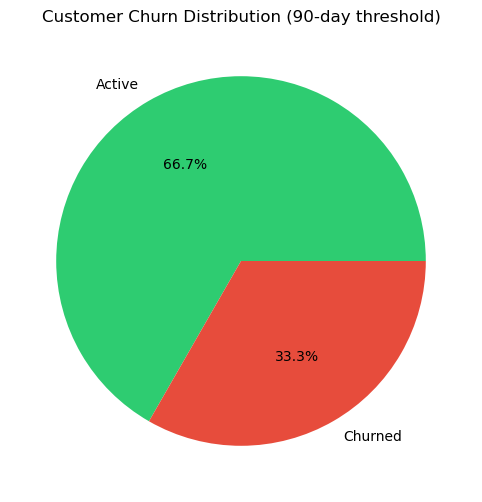

In [43]:
# Pie chart
churn_counts = customer_features['Churn'].value_counts()
labels = ['Active', 'Churned']
plt.figure(figsize=(8, 6))
plt.pie(churn_counts, labels=labels, autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'])
plt.title('Customer Churn Distribution (90-day threshold)')
plt.show()

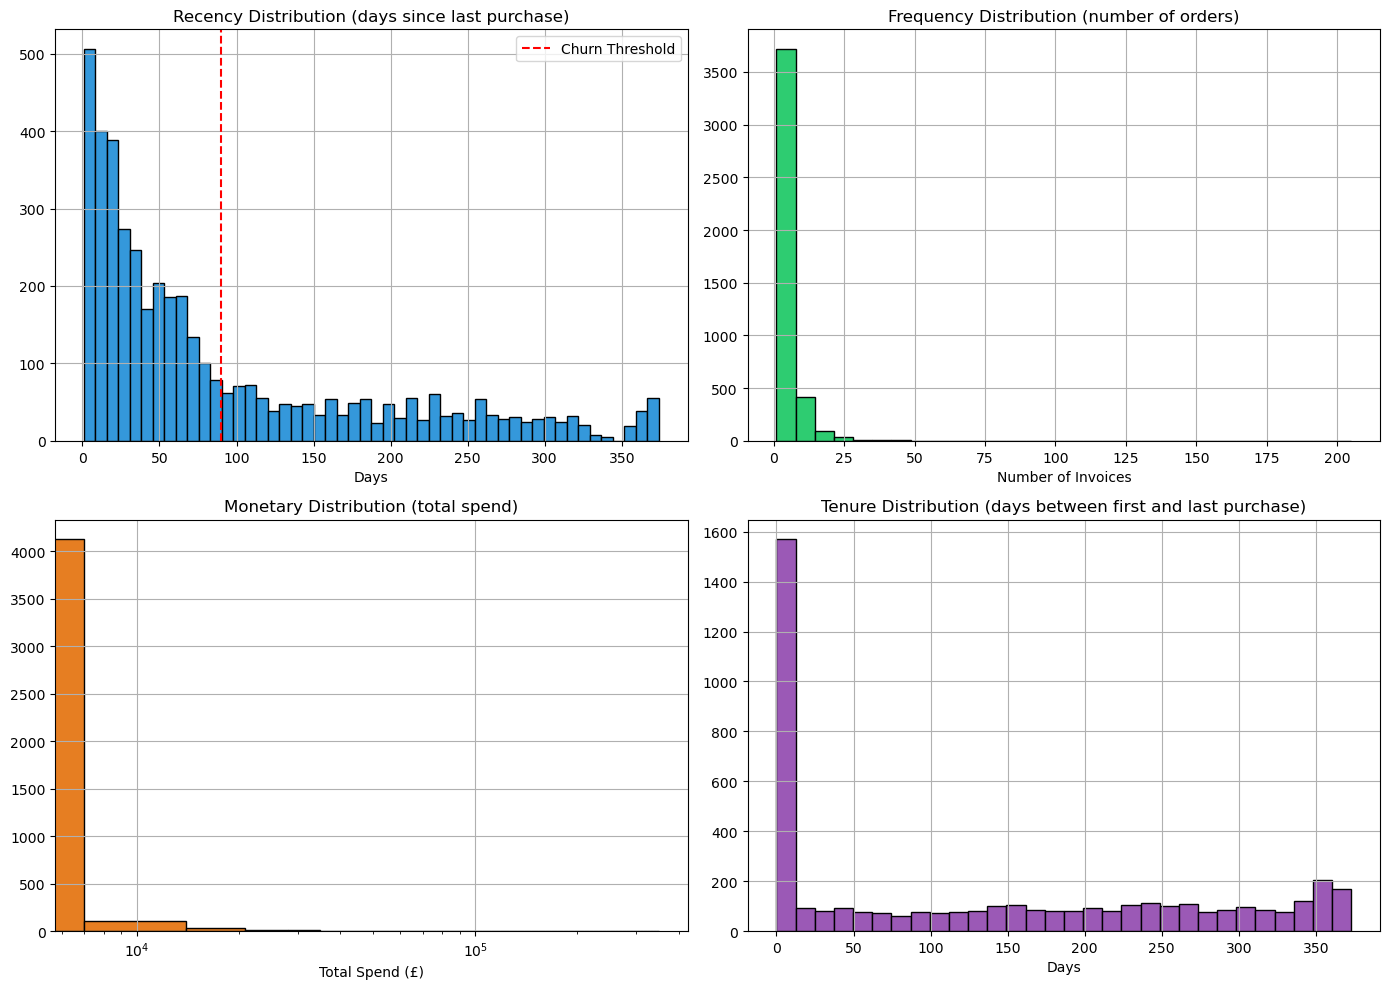

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Recency distribution
customer_features['Recency'].hist(bins=50, ax=axes[0,0], color='#3498db', edgecolor='black')
axes[0,0].set_title('Recency Distribution (days since last purchase)')
axes[0,0].set_xlabel('Days')
axes[0,0].axvline(x=90, color='red', linestyle='--', label='Churn Threshold')
axes[0,0].legend()

# Frequency distribution
customer_features['Frequency'].hist(bins=30, ax=axes[0,1], color='#2ecc71', edgecolor='black')
axes[0,1].set_title('Frequency Distribution (number of orders)')
axes[0,1].set_xlabel('Number of Invoices')

# Monetary distribution (log scale)
customer_features['Monetary'].hist(bins=50, ax=axes[1,0], color='#e67e22', edgecolor='black')
axes[1,0].set_title('Monetary Distribution (total spend)')
axes[1,0].set_xlabel('Total Spend (£)')
axes[1,0].set_xscale('log')

# Tenure distribution
customer_features['Tenure'].hist(bins=30, ax=axes[1,1], color='#9b59b6', edgecolor='black')
axes[1,1].set_title('Tenure Distribution (days between first and last purchase)')
axes[1,1].set_xlabel('Days')

plt.tight_layout()
plt.show()

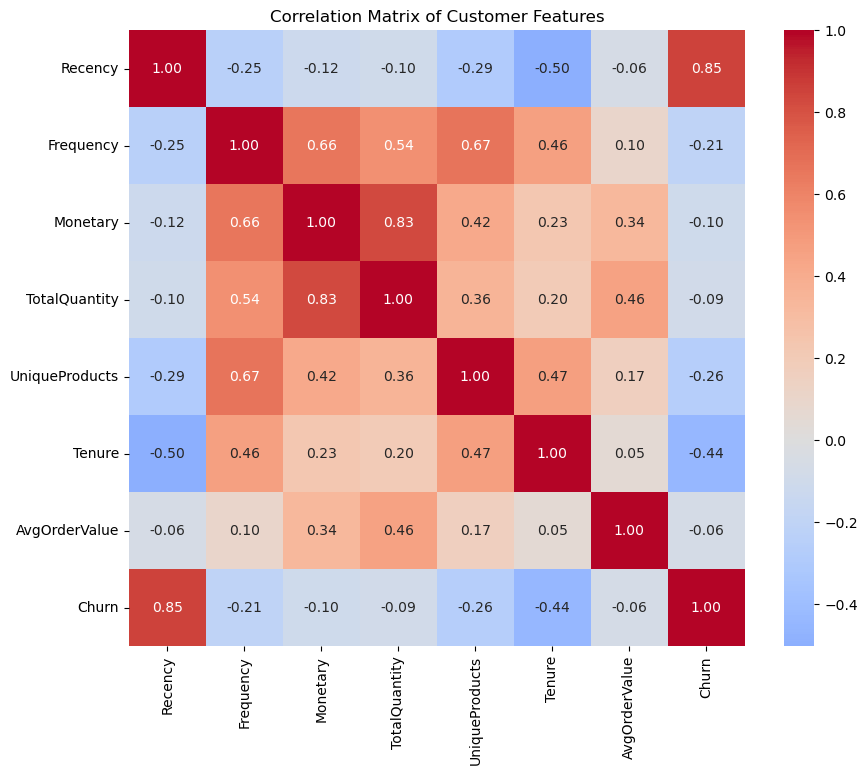

In [41]:
# Select numeric columns for correlation
numeric_cols = ['Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'Tenure', 'AvgOrderValue', 'Churn']
corr_matrix = customer_features[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
plt.title('Correlation Matrix of Customer Features')
plt.show()

In [40]:
import os

# Create the processed folder if it doesn't exist
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

# Save the CSV
output_path = os.path.join(output_dir, 'customer_features.csv')
customer_features.to_csv(output_path, index=False)

print(f"✅ Saved {len(customer_features):,} customer records to {output_path}")
print(f"📊 Columns: {list(customer_features.columns)}")

✅ Saved 4,310 customer records to ../data/processed\customer_features.csv
📊 Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'Country', 'Tenure', 'AvgOrderValue', 'Churn']


In [39]:
print("📊 Summary Statistics for Customer Features:")
print(customer_features.describe())

print("\n📋 Quick Preview of Churned vs Active Customers:")
churn_summary = customer_features.groupby('Churn').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Tenure': 'mean'
}).round(2)
print(churn_summary)

📊 Summary Statistics for Customer Features:
         CustomerID      Recency    Frequency       Monetary  TotalQuantity  \
count   4310.000000  4310.000000  4310.000000    4310.000000    4310.000000   
mean   15349.636891    91.234571     4.453364    2028.456147    1259.607425   
std     1701.221637    96.969169     8.159129    8847.570753    5892.914893   
min    12346.000000     1.000000     1.000000       0.000000       1.000000   
25%    13883.250000    18.000000     1.000000     307.542500     158.000000   
50%    15350.500000    53.000000     2.000000     703.810000     382.500000   
75%    16834.750000   136.000000     5.000000    1715.445000     996.750000   
max    18287.000000   374.000000   205.000000  349164.350000  170342.000000   

       UniqueProducts       Tenure  AvgOrderValue        Churn  
count     4310.000000  4310.000000    4310.000000  4310.000000  
mean        63.674014   134.002320     372.086733     0.332947  
std         85.771944   132.811236     446.080589

In [38]:
print("📊 Summary Statistics for Customer Features:")
print(customer_features.describe())

print("\n📋 Quick Preview of Churned vs Active Customers:")
churn_summary = customer_features.groupby('Churn').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Tenure': 'mean'
}).round(2)
print(churn_summary)

📊 Summary Statistics for Customer Features:
         CustomerID      Recency    Frequency       Monetary  TotalQuantity  \
count   4310.000000  4310.000000  4310.000000    4310.000000    4310.000000   
mean   15349.636891    91.234571     4.453364    2028.456147    1259.607425   
std     1701.221637    96.969169     8.159129    8847.570753    5892.914893   
min    12346.000000     1.000000     1.000000       0.000000       1.000000   
25%    13883.250000    18.000000     1.000000     307.542500     158.000000   
50%    15350.500000    53.000000     2.000000     703.810000     382.500000   
75%    16834.750000   136.000000     5.000000    1715.445000     996.750000   
max    18287.000000   374.000000   205.000000  349164.350000  170342.000000   

       UniqueProducts       Tenure  AvgOrderValue        Churn  
count     4310.000000  4310.000000    4310.000000  4310.000000  
mean        63.674014   134.002320     372.086733     0.332947  
std         85.771944   132.811236     446.080589

In [37]:
# ============================================
# FIX TENURE COLUMN
# ============================================

# 1. Calculate first and last purchase dates
first_purchase = df.groupby('CustomerID')['InvoiceDate'].min()
last_purchase = df.groupby('CustomerID')['InvoiceDate'].max()

# 2. Calculate tenure in days
tenure_days = (last_purchase - first_purchase).dt.days

# 3. Add to customer_features
customer_features['Tenure'] = customer_features['CustomerID'].map(tenure_days)

# 4. Fill NaN values (customers with only one purchase)
customer_features['Tenure'] = customer_features['Tenure'].fillna(0)

# 5. Verify
print("✅ Tenure fixed!")
print(customer_features[['CustomerID', 'Tenure']].head())
print(f"\nTenure statistics:\n{customer_features['Tenure'].describe()}")
print(f"Missing values: {customer_features['Tenure'].isnull().sum()}")

✅ Tenure fixed!
   CustomerID  Tenure
0     12346.0     196
1     12347.0      37
2     12348.0       0
3     12349.0     181
4     12351.0       0

Tenure statistics:
count    4310.000000
mean      134.002320
std       132.811236
min         0.000000
25%         0.000000
50%       105.000000
75%       253.750000
max       373.000000
Name: Tenure, dtype: float64
Missing values: 0


In [52]:
pip install xgboost


   ---------------------------------------- 0.0/69.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/69.5 MB 640.0 kB/s eta 0:01:49
   ---------------------------------------- 0.1/69.5 MB 1.7 MB/s eta 0:00:41
   ---------------------------------------- 0.6/69.5 MB 5.5 MB/s eta 0:00:13
    --------------------------------------- 1.1/69.5 MB 7.0 MB/s eta 0:00:10
   - -------------------------------------- 2.3/69.5 MB 10.4 MB/s eta 0:00:07
   - -------------------------------------- 3.3/69.5 MB 12.2 MB/s eta 0:00:06
   -- ------------------------------------- 3.7/69.5 MB 11.7 MB/s eta 0:00:06
   -- ------------------------------------- 4.6/69.5 MB 12.7 MB/s eta 0:00:06
   --- ------------------------------------ 5.7/69.5 MB 14.1 MB/s eta 0:00:05
   ---- ----------------------------------- 7.1/69.5 MB 15.7 MB/s eta 0:00:04
   ---- ----------------------------------- 7.3/69.5 MB 15.5 MB/s eta 0:00:05
   ---- ----------------------------------- 8.3/69.5 MB 15.6 MB/s eta 0:00

In [64]:
# Check current columns
print("Current columns in customer_features:")
print(customer_features.columns.tolist())

Current columns in customer_features:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'Country', 'Tenure_x', 'AvgOrderValue', 'Churn', 'Tenure_y']


In [65]:
# Remove duplicate Tenure columns and keep the correct one
# We want to keep 'Tenure_y' (the one we just merged) and drop 'Tenure_x'

customer_features = customer_features.drop('Tenure_x', axis=1)

# Rename 'Tenure_y' to just 'Tenure'
customer_features = customer_features.rename(columns={'Tenure_y': 'Tenure'})

# Check columns now
print("✅ Cleaned columns:")
print(customer_features.columns.tolist())

✅ Cleaned columns:
['CustomerID', 'Recency', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'Country', 'AvgOrderValue', 'Churn', 'Tenure']


Features: ['Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts', 'AvgOrderValue', 'Tenure']
Total customers: 4310
Churn rate: 33.29%
Any NaN in X: False

Training set: 3448 customers
Test set: 862 customers


c:\Users\pawar\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [22:43:57] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:793: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



📊 Model Performance Comparison (No Recency):
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression    0.7042     0.5526  0.5854    0.5685   0.7780
1        Random Forest    0.6914     0.5429  0.4634    0.5000   0.7697
2              XGBoost    0.6810     0.5261  0.4216    0.4681   0.7693

🔑 Feature Importance:
          Feature  Importance
5          Tenure    0.485747
3  UniqueProducts    0.116806
4   AvgOrderValue    0.105654
2   TotalQuantity    0.105227
1        Monetary    0.098325
0       Frequency    0.088241


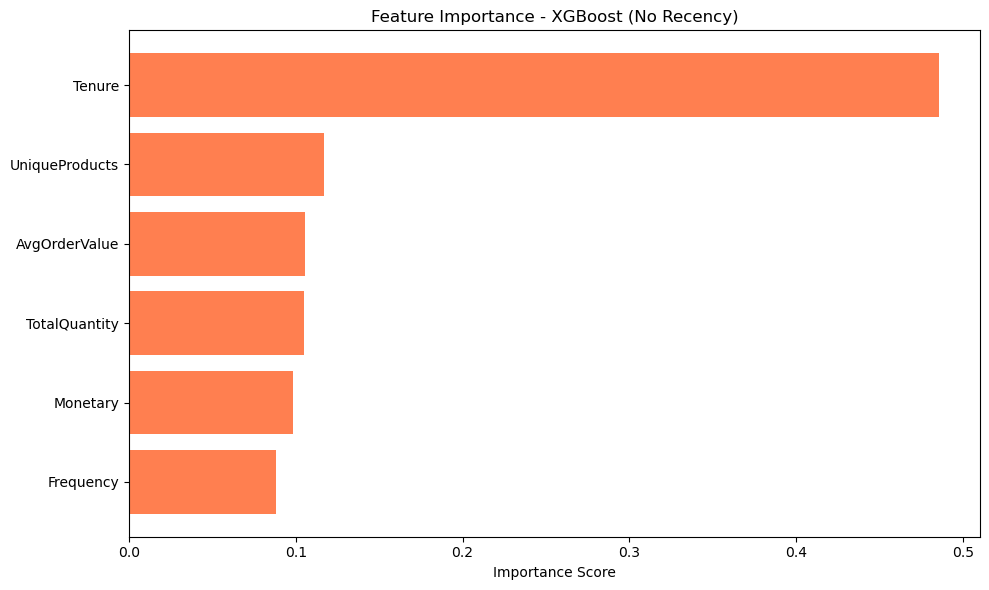


✅ Model saved as 'churn_model_no_recency.pkl'

💡 Business Insights:
1. Model can predict churn with 68.1% accuracy (without using Recency)
2. Top predictor: Tenure (importance: 48.57%)
3. Customer with: low frequency, low monetary value, short tenure = high churn risk
4. Action: Target these customers with re-engagement campaigns


In [67]:
# ============================================
# BUILD CHURN MODEL (WITHOUT RECENCY - FIXED)
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Features (EXCLUDING Recency to avoid data leakage)
features = ['Frequency', 'Monetary', 'TotalQuantity', 
            'UniqueProducts', 'AvgOrderValue', 'Tenure']

X = customer_features[features]
y = customer_features['Churn']

print(f"Features: {features}")
print(f"Total customers: {len(X)}")
print(f"Churn rate: {y.mean():.2%}")
print(f"Any NaN in X: {X.isnull().any().any()}")

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set: {X_train.shape[0]} customers")
print(f"Test set: {X_test.shape[0]} customers")

# 3. Train models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, random_state=42, use_label_encoder=False, eval_metric='logloss')
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

# 4. Results
results_df = pd.DataFrame(results)
print("\n📊 Model Performance Comparison (No Recency):")
print(results_df.round(4))

# 5. Feature Importance
best_model = models['XGBoost']
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': best_model.feature_importances_
}).sort_values('Importance', ascending=False)

print("\n🔑 Feature Importance:")
print(importance_df)

# 6. Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='coral')
plt.xlabel('Importance Score')
plt.title('Feature Importance - XGBoost (No Recency)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 7. Save model
import joblib
joblib.dump(best_model, 'churn_model_no_recency.pkl')
print("\n✅ Model saved as 'churn_model_no_recency.pkl'")

# 8. Business Insights
print("\n💡 Business Insights:")
print("=" * 50)
print(f"1. Model can predict churn with {results_df.iloc[2]['Accuracy']:.1%} accuracy (without using Recency)")
print(f"2. Top predictor: {importance_df.iloc[0]['Feature']} (importance: {importance_df.iloc[0]['Importance']:.2%})")
print("3. Customer with: low frequency, low monetary value, short tenure = high churn risk")
print("4. Action: Target these customers with re-engagement campaigns")